# SmartRepair AI — Data Analysis, PCA, Statistics, SQL Design & Baseline ML
### Dataset: Open Repair Alliance (ORDS v0.3, July 2025 release)

This notebook is the **data analysis and preprocessing component** of the SmartRepair AI project (improving an appliance-repair business with ML). It has been revised to fix the issues found in the code review.

**What this notebook does, in order**

| # | Section | Business question it supports |
|---|---|---|
| 1 | Setup & settings | — |
| 2 | Download & load data | — |
| 3 | Validate the data | Can we trust the files before using them? |
| 4 | Clean the data (one shared policy) | Same rules for every analysis |
| 5 | Exploratory data analysis (EDA) | What do repairs look like? |
| 6 | PCA (fixed) | Do the numeric features carry independent information? |
| 7 | Product age by category | Which products come in old vs. young? |
| 8 | Age distribution & goodness-of-fit | Is product age Poisson / Binomial? |
| 9 | Relational database design (SQL) | How do we store the data? |
| 10 | Baseline ML model | Can we predict whether a repair will succeed? |
| 11 | Summary of fixes | What changed and why |

**How to read each step.** Every code cell has a short note above it with four parts:
- **Purpose** — what the cell does.
- **Requirement** — what must already exist or be true for it to work.
- **Logic** — how it works, step by step.
- **Why this way** — why this approach was chosen over the alternatives.

> Run the cells from top to bottom. Later cells depend on variables created earlier.

---
## 1. Setup

### 1.1 Import libraries
**Purpose:** Load every library the notebook needs, in one place.

**Requirement:** These packages come pre-installed in Google Colab.

**Logic:** `pandas`/`numpy` handle tables and maths, `matplotlib`/`seaborn` draw charts, `scipy.stats` provides the Poisson/Binomial distributions and the chi-square test, and `scikit-learn` provides PCA, scaling and the ML model.

**Why this way:** The original notebook re-imported libraries in every cell. Importing once at the top is the standard convention: anyone reading the notebook immediately sees its dependencies, and nothing is imported twice.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import poisson, binom

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### 1.2 Project settings (one place for every rule)
**Purpose:** Define every threshold and file path once, as named constants.

**Requirement:** None — this cell only creates variables.

**Logic:** Each later cell reads these constants instead of typing numbers directly.

**Why this way:** This fixes **Review Error 5 (inconsistent product-age limits)**. The original code used `<= 40` in one cell and `> 50` in another, so the age analysis and the SQL/ML data followed different rules. With a single `AGE_MAX`, changing the rule in one place changes it everywhere.

*Why 40 years?* Repair cafés see some vintage items, but a product age above 40 years is far more likely a typing error (e.g. a year typed as an age) than a real appliance. Section 4.3 prints how many records each rule removes, so the cutoff is backed by the data rather than chosen blindly. `YEAR_MAX` uses the current year so the rule does not go stale.

In [ ]:
# ---- Data cleaning rules (used by EVERY section) ----
AGE_MIN = 0            # product age cannot be negative
AGE_MAX = 40           # ages above this are treated as data-entry errors
YEAR_MIN = 1950        # earliest plausible year of manufacture
YEAR_MAX = pd.Timestamp.today().year   # no product is made in the future

RANDOM_STATE = 42      # makes sampling / train-test split reproducible

# ---- File locations ----
DATA_DIR = "aggregate"
AGG_FILE = os.path.join(DATA_DIR, "OpenRepairData_v0.3_aggregate_202507.csv")
UNPOWERED_FILE = os.path.join(DATA_DIR, "OpenRepairData_v0.3_unpowered_202507.csv")
CATS_FILE = os.path.join(DATA_DIR, "OpenRepairData_v0.3_Product_Categories.csv")

---
## 2. Download and load the data

### 2.1 Download and unzip
**Purpose:** Get the Open Repair Alliance ZIP file from Google Drive and extract it.

**Requirement:** The Google Drive file must be shared as "Anyone with the link". Internet access is needed.

**Logic:**
- `pip install -q gdown` installs the downloader quietly (no long log).
- `gdown --id ... -O aggregate.zip` saves the download under a **fixed file name**.
- `unzip -o` extracts it and **overwrites** old files without stopping to ask.

**Why this way:** This fixes **Review Error 1**. The original `!gdown <id>` saved the file under whatever name Google Drive reported, and `!unzip` paused with a yes/no prompt if you ran the cell twice. Fixing the name with `-O` and adding `-o` makes the cell safe to re-run.

In [ ]:
!pip install -q gdown
!gdown --id 1_6lTc-fbUYN8A42sk4rsG9A4gpaBt7PT -O aggregate.zip
!unzip -o -q aggregate.zip

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1_6lTc-fbUYN8A42sk4rsG9A4gpaBt7PT
To: /content/aggregate.zip
100% 11.4M/11.4M [00:00<00:00, 109MB/s]


### 2.2 Confirm the files exist
**Purpose:** Check that the expected CSV files are where the code will look for them.

**Requirement:** Cell 2.1 has run.

**Logic:** List the folder, then check each of the three file paths. If one is missing, stop with a clear message.

**Why this way:** The review warned that the ZIP may contain a differently named or nested folder. Failing early with "file not found: …" is much easier to debug than a long pandas error later.

In [ ]:
print("Files in current folder:", os.listdir("."))
print("Files in", DATA_DIR, ":", os.listdir(DATA_DIR) if os.path.exists(DATA_DIR) else "FOLDER NOT FOUND")

for path in [AGG_FILE, UNPOWERED_FILE, CATS_FILE]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Expected file not found: {path}. Check the ZIP folder structure above.")
print("\nAll three data files found.")

Files in current folder: ['.config', 'aggregate', '__MACOSX', 'aggregate.zip', 'sample_data']
Files in aggregate : ['OpenRepairData_v0.3_unpowered_202507.csv', 'OpenRepairData_v0.3_Product_Categories.csv', 'OpenRepairData_v0.3_aggregate_202507.csv', 'tableschema.json']

All three data files found.


### 2.3 Read the CSV files
**Purpose:** Load the three files into pandas DataFrames.

**Requirement:** Cell 2.2 confirmed the files exist.

**Logic:**
- `df_raw` holds the main repair records (one row per repair attempt).
- `df_unpowered` holds a summary of non-electrical items. It is loaded for completeness but not used further, because it is a small summary table, not individual repair events.
- `df_cats` holds the product category list.

**Why this way:** The raw data is loaded **once** and never modified. Every analysis works on a cleaned copy (Section 4). The original notebook reloaded the CSV in several cells and cleaned it differently each time (**Review Issue 3**).

In [ ]:
df_raw = pd.read_csv(AGG_FILE, low_memory=False)
df_unpowered = pd.read_csv(UNPOWERED_FILE)
df_cats = pd.read_csv(CATS_FILE)

print("=== Dataset shapes (rows, columns) ===")
print(f"Repair records : {df_raw.shape}")
print(f"Unpowered      : {df_unpowered.shape}")
print(f"Categories     : {df_cats.shape}")

=== Dataset shapes (rows, columns) ===
Repair records : (305649, 14)
Unpowered      : (156, 4)
Categories     : (40, 2)


---
## 3. Validate the data before using it

### 3.1 Check that all required columns exist
**Purpose:** Make sure every column the notebook relies on is present.

**Requirement:** `df_raw` is loaded.

**Logic:** Compare a list of required column names with the actual columns. If any are missing, stop and name them.

**Why this way:** This fixes **Review Error 3**. Selecting a missing column raises a confusing `KeyError` deep inside a function. This check names the exact problem up front, which matters if a future data release renames a column.

In [ ]:
REQUIRED_COLS = [
    "id", "data_provider", "country", "product_category", "product_category_id",
    "brand", "year_of_manufacture", "product_age", "repair_status",
    "repair_barrier_if_end_of_life", "event_date", "problem",
]

missing_cols = [c for c in REQUIRED_COLS if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing columns in dataset: {missing_cols}")
print("All required columns are present.")
print("All columns:", df_raw.columns.tolist())

All required columns are present.
All columns: ['id', 'data_provider', 'country', 'partner_product_category', 'product_category', 'product_category_id', 'brand', 'year_of_manufacture', 'product_age', 'repair_status', 'repair_barrier_if_end_of_life', 'group_identifier', 'event_date', 'problem']


### 3.2 Check the category file before renaming its columns
**Purpose:** Confirm the category file has exactly two columns, in the order *ID then name*, before giving them standard names.

**Requirement:** `df_cats` is loaded.

**Logic:**
1. Show the original column names and first rows so you can see the order.
2. Stop if there are not exactly two columns.
3. Check that the first column is numeric (an ID) and the second is text (a name). If they are swapped, swap them back.
4. Rename them to `product_category_id` and `product_category`.

**Why this way:** This fixes **Review Error 2**. The original `df_cats.columns = [...]` crashes if the column count differs and, worse, **silently mislabels** the data if the order is reversed. Checking the data types catches the silent case.

In [ ]:
print("Original category columns:", df_cats.columns.tolist())
print(df_cats.head(), "\n")

if len(df_cats.columns) != 2:
    raise ValueError(f"Expected 2 columns in category file, found {len(df_cats.columns)}")

first, second = df_cats.columns
if not pd.api.types.is_numeric_dtype(df_cats[first]) and pd.api.types.is_numeric_dtype(df_cats[second]):
    print("Columns were in name-then-ID order; swapping them.")
    df_cats = df_cats[[second, first]]

df_cats.columns = ["product_category_id", "product_category"]

if not pd.api.types.is_numeric_dtype(df_cats["product_category_id"]):
    raise ValueError("product_category_id is not numeric. Check the category file.")
print("Category file validated:", df_cats.shape)

Original category columns: ['product_category_id', 'product_category']
   product_category_id             product_category
0                    1          Aircon/dehumidifier
1                    2      Battery/charger/adapter
2                    3  Decorative or safety lights
3                    4             Desktop computer
4                    5       Digital compact camera 

Category file validated: (40, 2)


### 3.3 Data types and missing values
**Purpose:** Understand each column's type and how much of it is missing.

**Requirement:** `df_raw` is loaded.

**Logic:** Build a small table with the type, missing count and missing percentage of every column, sorted by most missing.

**Why this way:** A percentage is easier to judge than a raw count. It is the key fact behind the cleaning decision in Section 4.4. `year_of_manufacture` and `product_age` are missing in roughly two-thirds of rows, which is too much to fill in blindly.

In [ ]:
missing_report = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(1),
}).sort_values("missing_%", ascending=False)
missing_report

,dtype,missing,missing_%
repair_barrier_if_end_of_life,object,275738,90.2
year_of_manufacture,float64,203515,66.6
product_age,float64,203537,66.6
problem,object,71779,23.5
id,object,0,0.0
data_provider,object,0,0.0
product_category_id,int64,0,0.0
product_category,object,0,0.0
partner_product_category,object,0,0.0
country,object,0,0.0


### 3.4 Identify which numeric columns are real measurements
**Purpose:** Separate genuine measurements from columns that only *look* numeric.

**Requirement:** `df_raw` is loaded.

**Logic:** List all numeric columns, then remove ones that are identifiers or codes.

**Why this way:** `product_category_id` is stored as a number, but it is a **label**: category 16 is not "bigger" than category 11. Treating it as a measurement in averages, imputation or PCA produces meaningless results (**Review Errors 4 and 7**). Keeping this list explicit means every later step uses the same, correct set of features.

In [ ]:
all_numeric = df_raw.select_dtypes(include=[np.number]).columns.tolist()
ID_OR_CODE_COLS = ["id", "product_category_id"]          # labels, not quantities
MEASUREMENT_COLS = [c for c in all_numeric if c not in ID_OR_CODE_COLS]

print("All numeric columns       :", all_numeric)
print("IDs / codes (excluded)    :", [c for c in all_numeric if c in ID_OR_CODE_COLS])
print("Real measurements (kept)  :", MEASUREMENT_COLS)

All numeric columns       : ['product_category_id', 'year_of_manufacture', 'product_age']
IDs / codes (excluded)    : ['product_category_id']
Real measurements (kept)  : ['year_of_manufacture', 'product_age']


---
## 4. Clean the data — one shared policy

The original notebook cleaned the data three different ways in three cells. Here, cleaning is split into **small functions**, each doing one job, and then combined into a single `clean_repairs()` function. **Every later section uses its output, `df`.** This fixes **Review Issue 3 (inconsistent cleaning)** and **Error 5 (inconsistent age limits)**.

### 4.1 Clean the event date
**Purpose:** Convert `event_date` from text into a real date and extract the year.

**Requirement:** The `event_date` column exists.

**Logic:** `pd.to_datetime(..., errors="coerce")` converts valid dates and turns unreadable ones into `NaT` (missing) instead of crashing. Then `event_year` is taken from the date.

**Why this way:** Real dates allow sorting, grouping by year, and a correct SQL `DATE` column. `errors="coerce"` keeps one bad row from stopping the whole notebook.

In [ ]:
def clean_dates(df):
    df = df.copy()
    df["event_date"] = pd.to_datetime(df["event_date"], errors="coerce")
    df["event_year"] = df["event_date"].dt.year
    return df

### 4.2 Clean the year of manufacture
**Purpose:** Remove impossible manufacturing years.

**Requirement:** `clean_dates()` has added `event_year`.

**Logic:** Set a year to missing (`NaN`) if it is before `YEAR_MIN`, after `YEAR_MAX`, or **after the repair year**, since a product cannot be repaired before it was made.

**Why this way:** Values are marked missing rather than deleting the row, because the row still has useful information (category, problem text, repair status). The third rule is a logical consistency check the original code did not have.

In [ ]:
def clean_year_of_manufacture(df):
    df = df.copy()
    bad = (
        (df["year_of_manufacture"] < YEAR_MIN)
        | (df["year_of_manufacture"] > YEAR_MAX)
        | (df["year_of_manufacture"] > df["event_year"])
    )
    df.loc[bad, "year_of_manufacture"] = np.nan
    return df

### 4.3 Clean the product age
**Purpose:** Remove impossible product ages using the single `AGE_MIN`–`AGE_MAX` rule.

**Requirement:** The `product_age` column exists, and the constants from 1.2 are defined.

**Logic:** Ages below 0 or above `AGE_MAX` become `NaN`. Ages are **kept as decimals**; nothing is converted to integers here.

**Why this way:** This fixes **Review Errors 5 and 6**. There is one threshold for every analysis, and the original precision is preserved. Converting to integers only happens later, inside the one analysis that truly needs whole numbers (Section 8), and it is documented there.

In [ ]:
def clean_product_age(df):
    df = df.copy()
    bad = (df["product_age"] < AGE_MIN) | (df["product_age"] > AGE_MAX)
    df.loc[bad, "product_age"] = np.nan
    return df

### 4.4 Clean text fields and handle missing values
**Purpose:** Tidy text columns and decide how to treat missing values.

**Requirement:** The text columns exist.

**Logic:**
- `brand` → strip spaces and make uppercase, so "Philips ", "philips" and "PHILIPS" count as one brand. Missing becomes `UNKNOWN`.
- `problem` → missing becomes `Unspecified`.
- `repair_barrier` → missing becomes `None`. This field is **only filled when a product is end-of-life**, so "missing" here genuinely means "no barrier".
- **Numeric columns (`product_age`, `year_of_manufacture`) are NOT filled with the median.**

**Why this way (important):** This fixes **Review Error 4**. Around 67% of ages are missing. Filling them all with the median (as the original code did) would invent two-thirds of the data, create a huge fake spike at one value, and distort every average, chart and the PCA. For statistics we analyse only rows where age is known. For ML (Section 10), missing ages are handled *inside* the model pipeline with a "was missing" flag, which is the honest approach.

In [ ]:
def clean_text_fields(df):
    df = df.copy()
    df["brand"] = df["brand"].fillna("Unknown").astype(str).str.strip().str.upper()
    df["problem"] = df["problem"].fillna("Unspecified").astype(str)
    df["repair_barrier"] = df["repair_barrier_if_end_of_life"].fillna("None")
    df = df.drop(columns=["repair_barrier_if_end_of_life"])
    return df

### 4.5 Combine the steps into one cleaning function and run it
**Purpose:** Run all cleaning steps in a fixed order and report what changed.

**Requirement:** Functions 4.1–4.4 are defined.

**Logic:** Pass the raw data through each function in turn, then print how many values each rule removed.

**Why this way:** One entry point (`clean_repairs`) guarantees that every analysis uses identical rules. The before/after counts make the cleaning transparent and justify the thresholds, as the review requested ("the cutoff should be justified by the dataset").

In [ ]:
def clean_repairs(df_raw):
    df = clean_dates(df_raw)
    df = clean_year_of_manufacture(df)
    df = clean_product_age(df)
    df = clean_text_fields(df)
    return df

df = clean_repairs(df_raw)

print("=== Effect of cleaning ===")
for col in ["product_age", "year_of_manufacture", "event_date"]:
    before = df_raw[col].notna().sum()
    after = df[col].notna().sum()
    print(f"{col:22s}: {before:>7,} known before -> {after:>7,} after ({before - after:,} removed as invalid)")

print(f"\nProduct ages above {AGE_MAX} in raw data: {(df_raw['product_age'] > AGE_MAX).sum():,} "
      f"({(df_raw['product_age'] > AGE_MAX).mean() * 100:.2f}% of all rows)")
print(f"Rows kept: {len(df):,} (no rows deleted, only invalid values marked missing)")

=== Effect of cleaning ===
product_age           : 102,112 known before ->  96,814 after (5,298 removed as invalid)
year_of_manufacture   : 102,134 known before -> 101,553 after (581 removed as invalid)
event_date            : 305,649 known before -> 305,649 after (0 removed as invalid)

Product ages above 40 in raw data: 5,298 (1.73% of all rows)
Rows kept: 305,649 (no rows deleted, only invalid values marked missing)


### 4.6 Check whether ages are whole numbers or decimals
**Purpose:** Find out whether `product_age` contains fractional values (e.g. 2.8 years).

**Requirement:** `df` exists.

**Logic:** Count known ages that are not whole numbers.

**Why this way:** The review raised two questions that depend on this fact: whether converting to integers loses information (Error 6), and whether the SQL column should be `INT` or `DECIMAL` (Error 10). Checking the data answers both instead of guessing.

In [ ]:
known_ages = df["product_age"].dropna()
n_fractional = (known_ages % 1 != 0).sum()
HAS_FRACTIONAL_AGES = n_fractional > 0

print(f"Known ages: {len(known_ages):,}")
print(f"Fractional (non-whole) ages: {n_fractional:,} ({n_fractional / len(known_ages) * 100:.2f}%)")
print("-> Use DECIMAL in SQL." if HAS_FRACTIONAL_AGES else "-> All whole years; INT would also be fine.")

Known ages: 96,814
Fractional (non-whole) ages: 1,929 (1.99%)
-> Use DECIMAL in SQL.


---
## 5. Exploratory data analysis (EDA)

### 5.1 Summary statistics of the real measurements
**Purpose:** Get count, mean, spread and range of the numeric measurements.

**Requirement:** `df` and `MEASUREMENT_COLS` exist.

**Logic:** `describe()` on the measurement columns only.

**Why this way:** The original called `describe()` on every numeric column *after* median-filling, so the statistics were computed partly from invented values and included the meaningless category ID. These numbers now describe real, known data only.

In [ ]:
df[MEASUREMENT_COLS].describe().round(2)

,year_of_manufacture,product_age
count,101553.00,96814.00
mean,2010.87,9.79
std,12.71,8.62
min,1950.00,0.00
25%,2008.00,4.00
50%,2015.00,7.00
75%,2019.00,13.00
max,2025.00,40.00


### 5.2 Repair outcome distribution
**Purpose:** See how repairs end: Fixed, Repairable, or End of life.

**Requirement:** `df` exists.

**Logic:** Count each `repair_status` value and plot it.

**Why this way:** This is the **target** for the ML model in Section 10. We need to know the classes and whether they are balanced before choosing evaluation metrics, as the review's ML checklist asks.

repair_status
Fixed          165144
End of life     77709
Repairable      54049
Unknown          8747
Name: count, dtype: int64 

repair_status
Fixed          54.0%
End of life    25.4%
Repairable     17.7%
Unknown         2.9%
Name: count, dtype: object


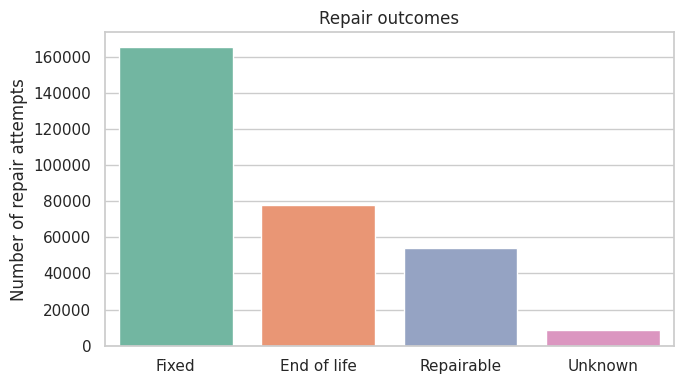

In [ ]:
status_counts = df["repair_status"].value_counts()
print(status_counts, "\n")
print((status_counts / status_counts.sum() * 100).round(1).astype(str) + "%")

plt.figure(figsize=(7, 4))
sns.barplot(x=status_counts.index, y=status_counts.values, hue=status_counts.index, palette="Set2", legend=False)
plt.title("Repair outcomes")
plt.ylabel("Number of repair attempts")
plt.xlabel("")
plt.tight_layout()
plt.show()

### 5.3 Most common product categories
**Purpose:** Find which products come in for repair most often.

**Requirement:** `df` exists.

**Logic:** Count rows per `product_category` and plot the top 15.

**Why this way:** For an appliance-repair business, volume per category drives staffing, technician training and parts stock. A horizontal bar chart keeps long category names readable.

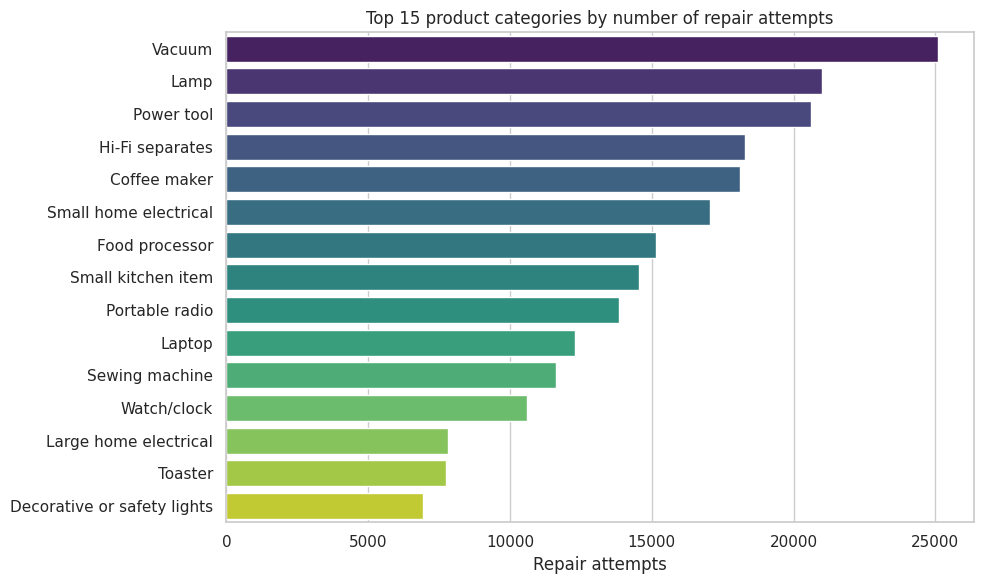

In [ ]:
top_cats = df["product_category"].value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_cats.values, y=top_cats.index, hue=top_cats.index, palette="viridis", legend=False)
plt.title("Top 15 product categories by number of repair attempts")
plt.xlabel("Repair attempts")
plt.ylabel("")
plt.tight_layout()
plt.show()

---
## 6. PCA (Principal Component Analysis) — fixed

PCA finds new axes ("principal components") that capture the most variation in a set of numeric features. If a few components explain most of the variance, the original features overlap heavily.

### 6.1 Choose the PCA input features
**Purpose:** Select only meaningful continuous features for PCA.

**Requirement:** `df` and `MEASUREMENT_COLS` exist.

**Logic:** Use the measurement columns plus `event_year`, and exclude IDs and category codes.

**Why this way:** This fixes **Review Error 7**. The original PCA included `product_category_id`, a label. PCA treats its numbers as distances, which is meaningless, and that is why it reported a large "component" that was really just the category code.

In [ ]:
PCA_COLS = MEASUREMENT_COLS + ["event_year"]
print("PCA features:", PCA_COLS)

PCA features: ['year_of_manufacture', 'product_age', 'event_year']


### 6.2 Prepare the data: keep complete rows and standardise
**Purpose:** Build a clean numeric matrix for PCA.

**Requirement:** `PCA_COLS` is defined.

**Logic:**
1. Keep only rows where **all** PCA features are known (`dropna`). No invented values.
2. Standardise each feature to mean 0 and standard deviation 1 with `StandardScaler`.

**Why this way:** PCA is driven by variance. Without scaling, a feature measured in large units (years ≈ 2000) would dominate a feature in small units, purely because of units. Using complete rows only avoids the median-imputation spike that distorted the original PCA.

In [ ]:
pca_df = df[PCA_COLS].dropna()
print(f"Rows with all PCA features known: {len(pca_df):,} of {len(df):,}")

if len(PCA_COLS) < 2 or len(pca_df) < 2:
    raise ValueError("Not enough features or rows for PCA.")

scaled_data = StandardScaler().fit_transform(pca_df)

Rows with all PCA features known: 96,811 of 305,649


### 6.3 Fit PCA and plot explained variance
**Purpose:** Measure how much variance each component explains.

**Requirement:** `scaled_data` exists.

**Logic:** Fit PCA, then plot each component's share (bars) and the running total (red line).

**Why this way:** The explained-variance plot (a "scree plot") is the standard way to decide how many components matter.

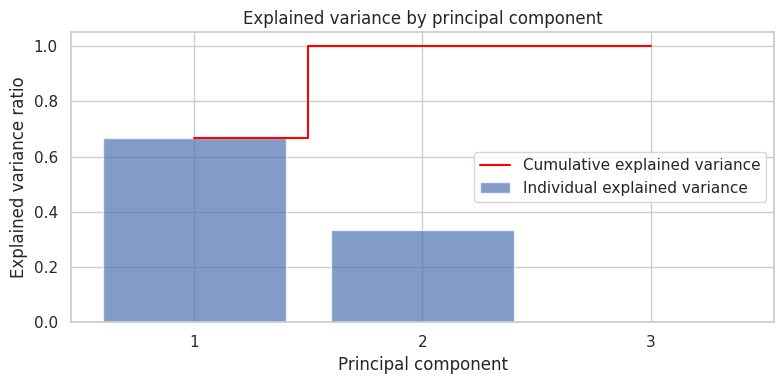

Explained variance ratio: [0.6671 0.3329 0.    ]


In [ ]:
pca = PCA(random_state=RANDOM_STATE)
pca_elements = pca.fit_transform(scaled_data)
ratios = pca.explained_variance_ratio_
idx = range(1, len(ratios) + 1)

plt.figure(figsize=(8, 4))
plt.bar(idx, ratios, alpha=0.7, label="Individual explained variance")
plt.step(idx, np.cumsum(ratios), where="mid", color="red", label="Cumulative explained variance")
plt.xticks(list(idx))
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("Explained variance by principal component")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", np.round(ratios, 4))

### 6.4 Interpret the result with a correlation check
**Purpose:** Explain *why* the PCA looks the way it does.

**Requirement:** `pca_df` exists.

**Logic:** Show the correlation matrix and the PCA loadings (how much each original feature contributes to each component).

**Why this way:** PCA results need interpretation, not just a chart. By definition, **product_age ≈ event_year − year_of_manufacture**, so the three features are almost linearly dependent and two components should explain nearly all the variance.

**Conclusion for the report:** PCA confirms these numeric features are **redundant**. This dataset has only one truly independent numeric signal (age), so PCA is used here as *exploratory evidence*, not as an input to the model. As the review notes, PCA does not automatically improve accuracy and is not needed if it does not help the downstream task.

In [ ]:
print("=== Correlation matrix ===")
print(pca_df.corr().round(3), "\n")

loadings = pd.DataFrame(pca.components_.T, index=PCA_COLS,
                        columns=[f"PC{i}" for i in idx]).round(3)
print("=== PCA loadings ===")
print(loadings)

=== Correlation matrix ===
                     year_of_manufacture  product_age  event_year
year_of_manufacture                1.000       -0.971       0.241
product_age                       -0.971        1.000      -0.003
event_year                         0.241       -0.003       1.000 

=== PCA loadings ===
                       PC1    PC2    PC3
year_of_manufacture  0.707 -0.003  0.707
product_age         -0.686  0.240  0.687
event_year           0.172  0.971 -0.168


---
## 7. Product age at repair, by category

### 7.1 Compute age statistics per category
**Purpose:** Find which product types arrive for repair when they are old vs. young.

**Requirement:** `df` exists with cleaned `product_age`.

**Logic:** Keep rows with a known age, group by category, compute mean, median and count, and keep only categories with at least 30 known ages.

**Why this way:** This uses the **same cleaned data** as every other section (the original reloaded the raw CSV here). The minimum of 30 records stops a category with 3 items from topping the chart by chance, since small samples give unreliable averages. The median is shown next to the mean because ages are right-skewed, so the mean is pulled up by a few very old items.

**Business use:** Old-at-repair categories (e.g. sewing machines, hi-fi) are durable and worth repairing. Young-at-repair categories (e.g. mobiles, headphones) may point to design weaknesses or common early faults, which is useful for parts stocking and technician training.

In [ ]:
MIN_RECORDS = 30
aged = df.dropna(subset=["product_age"])

cat_age_stats = (
    aged.groupby("product_category")["product_age"]
        .agg(["mean", "median", "count"])
        .query("count >= @MIN_RECORDS")
        .sort_values("mean", ascending=False)
        .round(2)
)
print(f"Categories with at least {MIN_RECORDS} known ages: {len(cat_age_stats)}\n")
print("=== 5 categories with the OLDEST average age at repair ===")
print(cat_age_stats.head(5), "\n")
print("=== 5 categories with the YOUNGEST average age at repair ===")
print(cat_age_stats.tail(5))

Categories with at least 30 known ages: 40

=== 5 categories with the OLDEST average age at repair ===
                    mean  median  count
product_category                       
Sewing machine     18.13    17.0   2856
Projector          17.27    12.0    279
Hi-Fi integrated   16.46    15.0   1328
Hi-Fi separates    15.53    13.0   5781
DSLR/video camera  15.47    15.0    282 

=== 5 categories with the YOUNGEST average age at repair ===
                     mean  median  count
product_category                        
Kettle               6.60     5.0   2142
Tablet               6.39     5.0   1185
Aircon/dehumidifier  6.33     5.0    510
Headphones           5.08     3.0   1172
Mobile               4.82     4.0   1495


### 7.2 Plot the oldest and youngest categories
**Purpose:** Visualise the top and bottom 15 categories by average age.

**Requirement:** `cat_age_stats` exists.

**Logic:** A small helper function draws one horizontal bar chart and is called twice.

**Why this way:** A helper avoids copy-pasting the same plotting code. It also fixes the seaborn `FutureWarning` in the original: `palette` without `hue` is deprecated, so we pass `hue=` the same column and hide the legend.

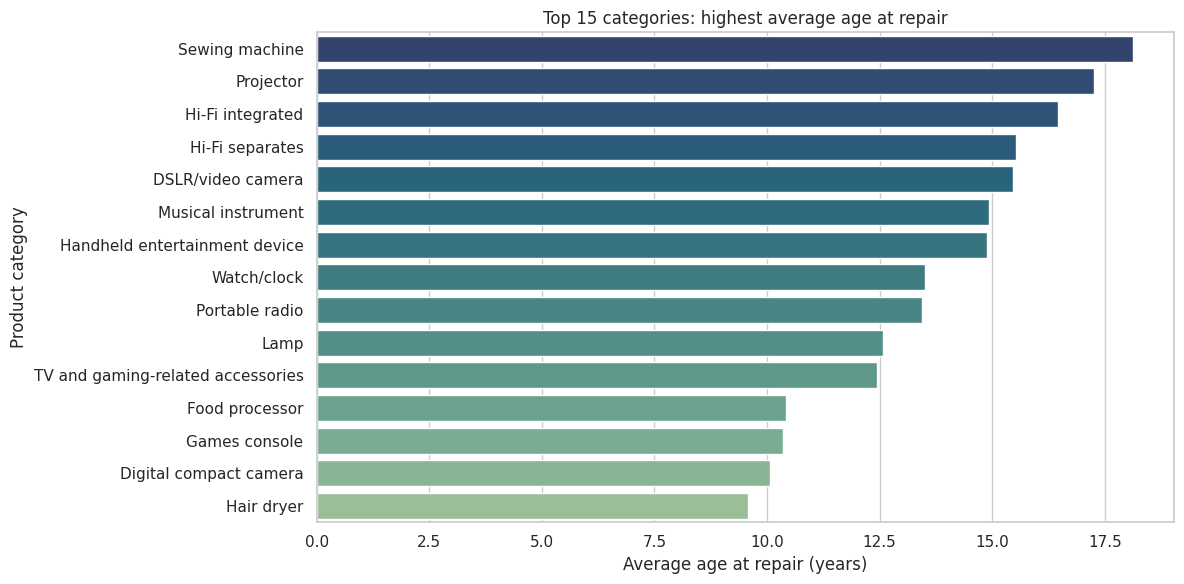

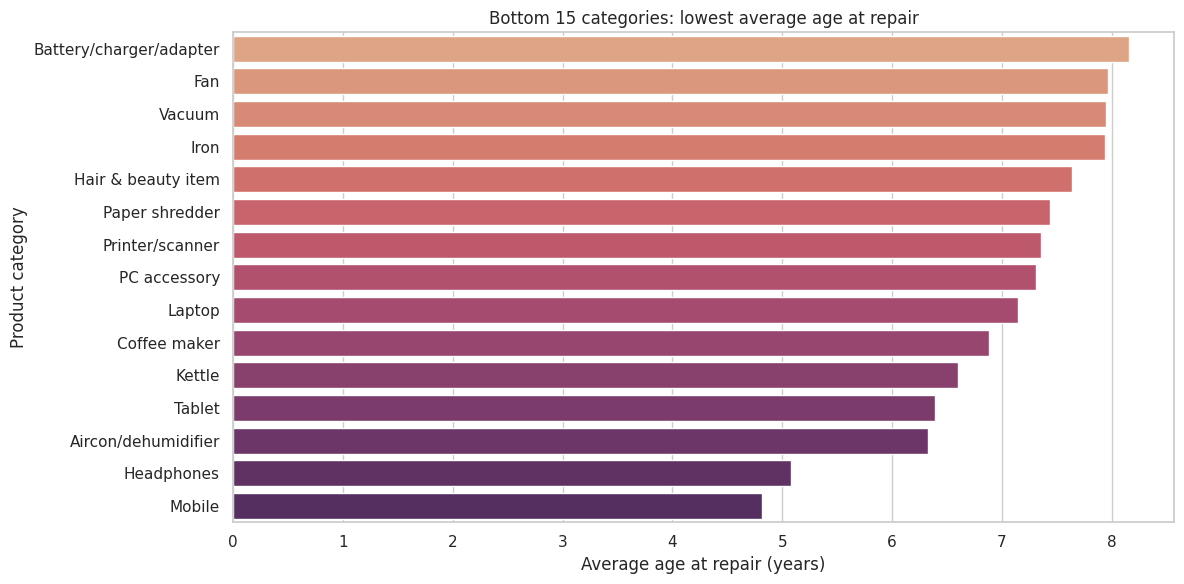

In [ ]:
def plot_category_ages(stats_df, title, palette):
    plt.figure(figsize=(12, 6))
    sns.barplot(x=stats_df["mean"].values, y=stats_df.index, hue=stats_df.index,
                palette=palette, legend=False)
    plt.title(title)
    plt.xlabel("Average age at repair (years)")
    plt.ylabel("Product category")
    plt.tight_layout()
    plt.show()

plot_category_ages(cat_age_stats.head(15), "Top 15 categories: highest average age at repair", "crest_r")
plot_category_ages(cat_age_stats.tail(15), "Bottom 15 categories: lowest average age at repair", "flare")

---
## 8. Distribution of product age — Poisson vs. Binomial, with a real fit test

The original notebook drew Poisson and Binomial curves over a histogram and stopped there. The review pointed out that **a histogram alone cannot prove a good fit** (Error 8). This section adds proper checks.

### 8.1 Prepare whole-year ages (documented choice)
**Purpose:** Create a whole-number version of age, needed only for these discrete distributions.

**Requirement:** `df` exists.

**Logic:** Use `np.floor()` to convert age into **completed years** (2.8 → 2), exactly like a person's age.

**Why this way:** Poisson and Binomial are **discrete** distributions: they only give probabilities for 0, 1, 2, … So integers are required here, and *only* here. This addresses **Review Error 6**: the conversion is explicit, uses a named rounding rule ("completed years", the normal meaning of age), and is not applied to the rest of the data. The original used `astype(int)` silently, which gives the same result for positive numbers but hid the decision.

In [ ]:
ages_cont = df["product_age"].dropna()              # continuous version, for summaries
ages = np.floor(ages_cont).astype(int)               # completed years, for discrete models

mean_age = ages.mean()
var_age = ages.var()
max_age = int(ages.max())
print(f"n = {len(ages):,}  |  mean = {mean_age:.2f}  |  variance = {var_age:.2f}  |  max = {max_age}")

n = 96,814  |  mean = 9.78  |  variance = 74.40  |  max = 40


### 8.2 Quick theory check: compare mean and variance
**Purpose:** Test a basic property each distribution must satisfy.

**Requirement:** `mean_age` and `var_age` from 8.1.

**Logic:**
- A **Poisson** distribution has variance = mean.
- A **Binomial** distribution has variance = n·p·(1−p), which is always **less than** the mean.
- The ratio variance ÷ mean is the *dispersion index*.

**Why this way:** This is a one-line check that often settles the question before any plotting. If variance is much larger than the mean ("overdispersion"), neither Poisson nor Binomial can fit well, and a **Negative Binomial** distribution (a Poisson whose rate varies between products) is the standard alternative, so we add it as a third candidate.

In [ ]:
dispersion = var_age / mean_age
print(f"Dispersion index (variance / mean) = {dispersion:.2f}")
if dispersion > 1.5:
    print("-> Strong overdispersion: Poisson (needs ~1) and Binomial (needs <1) are unlikely to fit.")
elif dispersion < 0.8:
    print("-> Underdispersion: Binomial may fit better than Poisson.")
else:
    print("-> Close to 1: Poisson is plausible.")

Dispersion index (variance / mean) = 7.61
-> Strong overdispersion: Poisson (needs ~1) and Binomial (needs <1) are unlikely to fit.


### 8.3 Fit the three candidate distributions
**Purpose:** Compute the probability each model assigns to every age 0…max.

**Requirement:** `mean_age`, `var_age`, `max_age` from 8.1.

**Logic:**
- **Poisson:** rate μ = mean age.
- **Binomial:** n = max age, p = mean ÷ n (so the model mean equals the data mean). This is the original notebook's choice.
- **Negative Binomial:** parameters chosen so its mean *and* variance match the data (method of moments).

**Why this way:** Method of moments is the simplest fitting approach that is easy to explain in a report. Matching the mean is fair to all three models. The Negative Binomial gets the extra advantage of matching the variance, which is exactly the property the other two lack.

In [ ]:
x_vals = np.arange(0, max_age + 1)

poisson_pmf = poisson.pmf(x_vals, mu=mean_age)

p_binom = mean_age / max_age
binom_pmf = binom.pmf(x_vals, n=max_age, p=p_binom)

if var_age > mean_age:
    nb_p = mean_age / var_age
    nb_r = mean_age * nb_p / (1 - nb_p)
    nbinom_pmf = stats.nbinom.pmf(x_vals, nb_r, nb_p)
    print(f"Negative Binomial fitted: r = {nb_r:.2f}, p = {nb_p:.3f}")
else:
    nbinom_pmf = None
    print("Variance <= mean, so Negative Binomial is not applicable.")

Negative Binomial fitted: r = 1.48, p = 0.131


### 8.4 Plot observed vs. fitted, showing the full age range
**Purpose:** Visually compare the data with each model.

**Requirement:** Results from 8.3.

**Logic:** Draw the observed share of each age as bars and each model as a line.

**Why this way:** This fixes **Review Error 9**. The original cut the x-axis at 30 (`xlim(-0.5, 30)`) while the data goes up to 40, hiding the right tail, which is exactly where models disagree. The axis now runs to `max_age`.

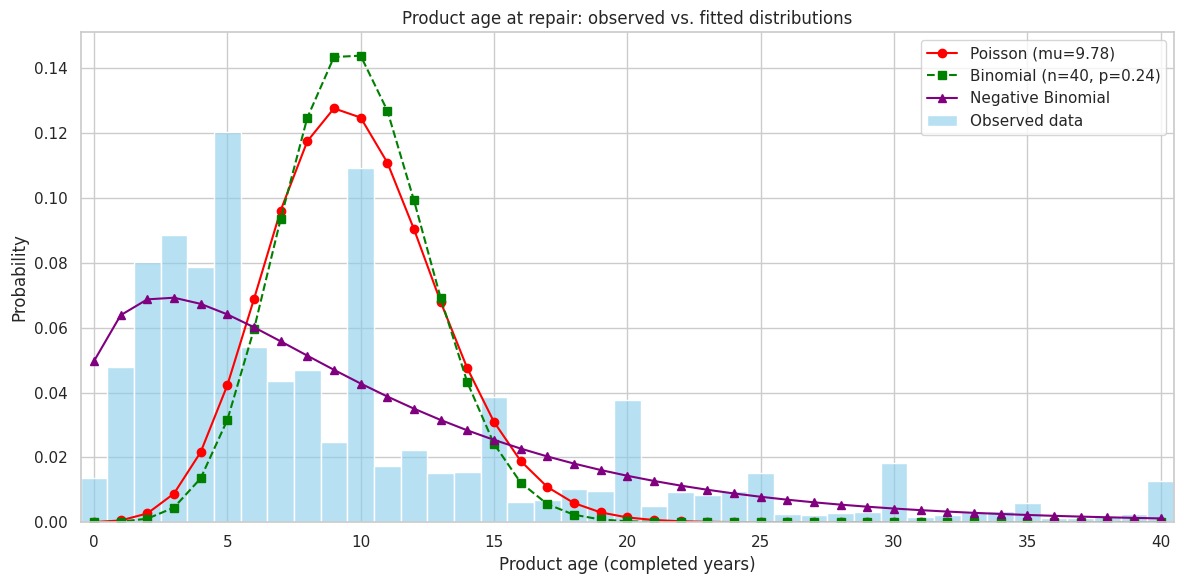

Skewness = 1.54 (positive -> long tail of older products)


In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(ages, stat="probability", discrete=True, color="skyblue", alpha=0.6, label="Observed data")
plt.plot(x_vals, poisson_pmf, "o-", color="red", label=f"Poisson (mu={mean_age:.2f})")
plt.plot(x_vals, binom_pmf, "s--", color="green", label=f"Binomial (n={max_age}, p={p_binom:.2f})")
if nbinom_pmf is not None:
    plt.plot(x_vals, nbinom_pmf, "^-", color="purple", label="Negative Binomial")

plt.xlim(-0.5, max_age + 0.5)
plt.title("Product age at repair: observed vs. fitted distributions")
plt.xlabel("Product age (completed years)")
plt.ylabel("Probability")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Skewness = {ages_cont.skew():.2f} (positive -> long tail of older products)")

### 8.5 Goodness-of-fit test (chi-square) and a practical measure
**Purpose:** Measure numerically how well each model fits, as the review requires.

**Requirement:** Results from 8.3.

**Logic:**
1. **Chi-square test:** compare observed counts per age with the counts each model expects. Rare ages at both ends are merged into groups so every expected count is at least 5, which is a rule of the test. One degree of freedom is subtracted per estimated parameter.
2. **Total variation distance (TVD):** half the sum of absolute probability differences. 0 = identical, 1 = completely different.

**Why this way:** With ~100,000 records, the chi-square test is so sensitive that it rejects *any* model with tiny imperfections (p ≈ 0). That's why we also report TVD, an easy-to-explain "how far off is it?" number, and **compare models with each other** instead of asking "is this one perfect?". The model with the lowest chi-square and TVD is the best description.

In [ ]:
def goodness_of_fit(observed_ages, pmf, n_params, min_expected=5):
    n = len(observed_ages)
    observed = np.bincount(observed_ages, minlength=len(pmf)).astype(float)
    expected = pmf / pmf.sum() * n                  # rescale so totals match

    # Merge sparse tails so every group has expected count >= min_expected
    obs_g, exp_g = list(observed), list(expected)
    while len(exp_g) > 2 and exp_g[-1] < min_expected:     # right tail
        e, o = exp_g.pop(), obs_g.pop()
        exp_g[-1] += e
        obs_g[-1] += o
    while len(exp_g) > 2 and exp_g[0] < min_expected:      # left tail
        e, o = exp_g.pop(0), obs_g.pop(0)
        exp_g[0] += e
        obs_g[0] += o
    obs_g, exp_g = np.array(obs_g), np.array(exp_g)

    chi2 = ((obs_g - exp_g) ** 2 / exp_g).sum()
    dof = len(obs_g) - 1 - n_params
    p_value = stats.chi2.sf(chi2, dof)
    tvd = 0.5 * np.abs(observed / n - pmf / pmf.sum()).sum()
    return {"chi_square": round(chi2, 1), "dof": dof, "p_value": p_value, "TVD": round(tvd, 3)}

results = {
    "Poisson": goodness_of_fit(ages.values, poisson_pmf, n_params=1),
    "Binomial": goodness_of_fit(ages.values, binom_pmf, n_params=1),
}
if nbinom_pmf is not None:
    results["Negative Binomial"] = goodness_of_fit(ages.values, nbinom_pmf, n_params=2)

fit_table = pd.DataFrame(results).T.sort_values("TVD")
print(fit_table)
print(f"\nBest-fitting model (lowest TVD): {fit_table.index[0]}")

                   chi_square   dof  p_value    TVD
Negative Binomial     47461.1  38.0      0.0  0.238
Poisson            10187063.2  23.0      0.0  0.519
Binomial           12987470.7  19.0      0.0  0.560

Best-fitting model (lowest TVD): Negative Binomial


---
## 9. Relational database design (SQL)

Schema (star design: one dimension table, one fact table):

```
dim_product_categories                 fact_repair_events
------------------------               --------------------------------
product_category_id  INT  PK  <------  product_category_id  INT  FK
product_category     VARCHAR           id                   VARCHAR PK
                                       data_provider, country, brand
                                       year_of_manufacture  INT
                                       product_age          DECIMAL(5,2)
                                       repair_status, repair_barrier
                                       event_date           DATE
                                       problem              TEXT
```

### 9.1 Build the two tables from the cleaned data
**Purpose:** Shape the cleaned data into the exact columns of the database tables.

**Requirement:** `df` and `df_cats` exist.

**Logic:** Select the fact-table columns from `df`, and store `year_of_manufacture` as a nullable integer (`Int64`, capital I) so missing values stay empty instead of forcing decimals.

**Why this way:** The SQL data now comes from the **same** `clean_repairs()` output as the analysis. The original rebuilt it with its own rules, including a different age cutoff of 50.

In [ ]:
categories_df = df_cats.copy()

repairs_df = df[[
    "id", "data_provider", "country", "product_category_id", "brand",
    "year_of_manufacture", "product_age", "repair_status", "repair_barrier",
    "event_date", "problem",
]].copy()
repairs_df["year_of_manufacture"] = repairs_df["year_of_manufacture"].round().astype("Int64")

print(f"Fact table rows: {len(repairs_df):,}  |  Category rows: {len(categories_df)}")
repairs_df.head()

Fact table rows: 305,649  |  Category rows: 40


,id,data_provider,country,product_category_id,brand,year_of_manufacture,product_age,repair_status,repair_barrier,event_date,problem
0,anstiftung_26663,anstiftung,DEU,11,MARLEY,<NA>,NaN,End of life,None,2025-07-28,wackelkontakt am kopfhörer.
1,anstiftung_26666,anstiftung,DEU,16,DELL,<NA>,NaN,End of life,None,2025-07-28,kaputt. hardware.
2,anstiftung_26770,anstiftung,DEU,40,HILO,<NA>,NaN,Repairable,None,2025-07-28,Bügeleisen wird nicht mehr heiß. Schalter defekt.
3,anstiftung_26627,anstiftung,DEU,37,THERMOMIX,<NA>,NaN,Fixed,None,2025-07-28,Herstellung der endgültigen Kipphilfe aus Alth...
4,anstiftung_26664,anstiftung,DEU,16,ACER,<NA>,NaN,Fixed,None,2025-07-28,kubuntu installiert.


### 9.2 Validate keys before loading into a database
**Purpose:** Make sure the data will not break the database's rules.

**Requirement:** `repairs_df` and `categories_df` from 9.1.

**Logic:**
1. **Primary key check:** every `id` must be unique and non-empty.
2. **Foreign key check:** every `product_category_id` in repairs must exist in the category table (Review Error 11).
3. **Category consistency:** the category *name* attached to each repair should match the name in the category table for that ID (completes the Error 2 check).

**Why this way:** A database rejects the whole import if one row breaks a key rule. Checking in Python first tells you exactly which values are the problem, which is much faster to fix.

In [ ]:
# 1. Primary key
dup_ids = repairs_df["id"].duplicated().sum()
null_ids = repairs_df["id"].isna().sum()
print(f"Duplicate ids: {dup_ids:,}  |  Missing ids: {null_ids:,}")

# 2. Foreign key
valid_ids = set(categories_df["product_category_id"].dropna())
repair_ids = set(repairs_df["product_category_id"].dropna())
invalid_ids = repair_ids - valid_ids
print("Category IDs in repairs but not in category table:", invalid_ids or "none")

# 3. Name consistency between the two files
name_check = (df[["product_category_id", "product_category"]].drop_duplicates()
              .merge(categories_df, on="product_category_id", how="left", suffixes=("_repairs", "_cats")))
mismatch = name_check[name_check["product_category_repairs"] != name_check["product_category_cats"]]
print(f"ID-to-name mismatches: {len(mismatch)}")
if len(mismatch):
    print(mismatch.head(10))

if dup_ids or null_ids or invalid_ids:
    print("\nWARNING: fix the issues above before loading into the database.")
else:
    print("\nKeys are valid. Safe to load.")

Duplicate ids: 0  |  Missing ids: 0
Category IDs in repairs but not in category table: none
ID-to-name mismatches: 0

Keys are valid. Safe to load.


### 9.3 Generate the SQL table definitions (DDL)
**Purpose:** Print the `CREATE TABLE` statements for PostgreSQL / MySQL.

**Requirement:** `HAS_FRACTIONAL_AGES` from 4.6.

**Logic:** `product_age` is written as `DECIMAL(5,2)` if fractional ages exist, otherwise `INT`.

**Why this way:** This fixes **Review Error 10**. `INT` would silently cut 2.8 to 2 on import. The choice is now made from the data itself (Section 4.6). `DECIMAL(5,2)` holds values up to 999.99 with two decimals, more than enough for ages up to 40.

In [ ]:
age_sql_type = "DECIMAL(5,2)" if HAS_FRACTIONAL_AGES else "INT"

ddl = f'''
-- DDL for PostgreSQL / MySQL
CREATE TABLE dim_product_categories (
    product_category_id INT PRIMARY KEY,
    product_category    VARCHAR(255) NOT NULL
);

CREATE TABLE fact_repair_events (
    id                  VARCHAR(100) PRIMARY KEY,
    data_provider       VARCHAR(150),
    country             VARCHAR(10),
    product_category_id INT NOT NULL,
    brand               VARCHAR(150),
    year_of_manufacture INT,
    product_age         {age_sql_type},
    repair_status       VARCHAR(100),
    repair_barrier      VARCHAR(255),
    event_date          DATE,
    problem             TEXT,
    FOREIGN KEY (product_category_id)
        REFERENCES dim_product_categories(product_category_id)
);
'''
print(ddl)


-- DDL for PostgreSQL / MySQL
CREATE TABLE dim_product_categories (
    product_category_id INT PRIMARY KEY,
    product_category    VARCHAR(255) NOT NULL
);

CREATE TABLE fact_repair_events (
    id                  VARCHAR(100) PRIMARY KEY,
    data_provider       VARCHAR(150),
    country             VARCHAR(10),
    product_category_id INT NOT NULL,
    brand               VARCHAR(150),
    year_of_manufacture INT,
    product_age         DECIMAL(5,2),
    repair_status       VARCHAR(100),
    repair_barrier      VARCHAR(255),
    event_date          DATE,
    problem             TEXT,
    FOREIGN KEY (product_category_id)
        REFERENCES dim_product_categories(product_category_id)
);



### 9.4 Export the cleaned tables
**Purpose:** Save the cleaned tables as CSV files, ready for database import or for teammates.

**Requirement:** `repairs_df` and `categories_df` exist.

**Logic:** Write both CSVs. In Colab, also trigger browser downloads.

**Why this way:** The original crashed outside Colab because `google.colab` does not exist elsewhere. The `try/except` lets the same notebook run in Colab, Jupyter or VS Code.

In [ ]:
repairs_df.to_csv("cleaned_repairs.csv", index=False)
categories_df.to_csv("cleaned_categories.csv", index=False)
print("Saved cleaned_repairs.csv and cleaned_categories.csv")

try:
    from google.colab import files
    files.download("cleaned_repairs.csv")
    files.download("cleaned_categories.csv")
except ImportError:
    print("Not running in Colab; files are saved in the current folder.")

Saved cleaned_repairs.csv and cleaned_categories.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 10. Baseline ML model: predict whether a repair will be fixed

The review's most important point (**Section 6**) was that the notebook analysed data but **never trained a model**. This section adds a simple, honest baseline.

**Business use:** When a customer books a repair, predict how likely it is to be fixed. A repair business can use this to quote more accurately, warn customers early about likely end-of-life items, and send harder jobs to senior technicians.

### 10.1 Define the target
**Purpose:** Turn `repair_status` into a yes/no target.

**Requirement:** `df` exists. Section 5.2 showed the classes.

**Logic:** `fixed = 1` if status is "Fixed", else `0`. "Repairable" (needs more parts/time) and "End of life" both mean *not fixed at this visit*.

**Why this way:** A binary target is the clearest first model and matches the business question "will this job be completed?". Labels are checked for consistency first (review checklist item 1), and unexpected values are printed so they can't slip in unnoticed.

In [ ]:
print("repair_status values:", df["repair_status"].unique().tolist())
expected = {"Fixed", "Repairable", "End of life"}
unexpected = set(df["repair_status"].unique()) - expected
if unexpected:
    print("Note: unexpected status values found:", unexpected)

ml_df = df.copy()
ml_df["fixed"] = (ml_df["repair_status"] == "Fixed").astype(int)
print(f"\nShare fixed: {ml_df['fixed'].mean():.1%}  |  Not fixed: {1 - ml_df['fixed'].mean():.1%}")

repair_status values: ['End of life', 'Repairable', 'Fixed', 'Unknown']
Note: unexpected status values found: {'Unknown'}

Share fixed: 54.0%  |  Not fixed: 46.0%


### 10.2 Choose features carefully (avoid data leakage)
**Purpose:** Pick the inputs the model may use.

**Requirement:** `ml_df` exists.

**Logic:** Use only information known **when the customer books the repair**:
- `product_category`, `brand`, `country` → categories
- `product_age` → number (may be missing)
- `problem` → the customer's description, as text

**Deliberately excluded:**
- `repair_barrier` → only filled *after* an item is declared end-of-life. It **reveals the answer** (data leakage) and would make the model look falsely perfect.
- `id`, `group_identifier` → identifiers, with no predictive meaning.
- `year_of_manufacture`, `event_year` → redundant with age (PCA in Section 6 proved this).
- `data_provider` → describes *which organisation recorded the data*, not the product, so the model would learn recording habits.

**Why this way:** This applies review checklist item 2: "input features should actually be available when making a prediction".

In [ ]:
CAT_FEATURES = ["product_category", "brand", "country"]
NUM_FEATURES = ["product_age"]
TEXT_FEATURE = "problem"
TARGET = "fixed"

X = ml_df[CAT_FEATURES + NUM_FEATURES + [TEXT_FEATURE]]
y = ml_df[TARGET]
print("Feature matrix:", X.shape)

Feature matrix: (305649, 5)


### 10.3 Split into training and test sets
**Purpose:** Hold back 20% of data to test the model on records it has never seen.

**Requirement:** `X` and `y` exist.

**Logic:** `train_test_split` with `stratify=y` keeps the same fixed/not-fixed ratio in both sets.

**Why this way:** Testing on unseen data is the only honest way to measure performance. Stratifying matters when classes are unequal. Crucially, **all preprocessing (scaling, imputation, text vocabulary) is learned from the training set only** inside a `Pipeline` (next cell), which prevents test data leaking into training (review checklist item 4).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows  |  Test: {len(X_test):,} rows")

Train: 244,519 rows  |  Test: 61,130 rows


### 10.4 Build the preprocessing steps
**Purpose:** Convert each feature type into numbers the model can use.

**Requirement:** Feature lists from 10.2.

**Logic:**
- **Categories → One-hot encoding.** Each category becomes a 0/1 column. Brands seen fewer than 50 times are grouped as "infrequent", so thousands of rare brands do not create thousands of noisy columns.
- **Age → median imputation + missing flag, then scaling.** Missing ages are filled with the *training* median, **and** an extra column records "age was missing". The model can learn whether missing age itself matters.
- **Problem text → TF-IDF.** Words and two-word phrases get weights: common in this description but rare overall means a high weight. Top 20,000 terms.

**Why this way:** This is where median imputation is acceptable. Unlike in Section 4, the "was missing" flag keeps the model honest about invented values, and the median comes from training data only. TF-IDF is the standard, explainable baseline for text, and it handles the multilingual descriptions (German, Dutch, English…) because it works on any words.

In [ ]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CAT_FEATURES),
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), NUM_FEATURES),
    ("text", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5,
                             sublinear_tf=True), TEXT_FEATURE),
])

### 10.5 Train a "dumb" baseline first
**Purpose:** Find the score a model gets by **always guessing the most common class**.

**Requirement:** Train/test sets exist.

**Logic:** `DummyClassifier(strategy="most_frequent")` ignores all inputs.

**Why this way:** Without this reference, a 65% accuracy might sound good, but it could be no better than always saying "Fixed". Any real model **must beat this** to be useful (review: "evaluate a baseline model").

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print("=== Baseline: always predict the most common class ===")
print(classification_report(y_test, dummy_pred, target_names=["Not fixed", "Fixed"], zero_division=0))

=== Baseline: always predict the most common class ===
              precision    recall  f1-score   support

   Not fixed       0.00      0.00      0.00     28101
       Fixed       0.54      1.00      0.70     33029

    accuracy                           0.54     61130
   macro avg       0.27      0.50      0.35     61130
weighted avg       0.29      0.54      0.38     61130



### 10.6 Train the Logistic Regression model
**Purpose:** Train the real model.

**Requirement:** `preprocess` from 10.4.

**Logic:** A `Pipeline` chains preprocessing → Logistic Regression. `class_weight="balanced"` gives the smaller class more importance during training.

**Why this way:** Logistic Regression is fast on 300k rows with 20k text features, works very well with TF-IDF, and is **explainable**: we can see which words push predictions up or down (10.8). It is the standard first model before trying more complex ones like XGBoost. Balanced class weights stop the model from ignoring the "not fixed" class just because it is smaller (review checklist item 3: class imbalance).

*This cell may take 1–3 minutes on the full dataset.*

In [ ]:
model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
model.fit(X_train, y_train)
print("Model trained.")

Model trained.


### 10.7 Evaluate with precision, recall, F1 and a confusion matrix
**Purpose:** Measure performance on the unseen test set.

**Requirement:** `model` is trained.

**Logic:**
- **Precision** = of the jobs predicted "Fixed", how many really were.
- **Recall** = of the jobs really fixed, how many the model caught.
- **F1** = balance of the two.
- **Confusion matrix** = counts of correct and wrong predictions for each class.

**Why this way:** Accuracy alone is misleading with unequal classes, so the review asked for these metrics specifically (checklist item 5). The macro-F1 comparison against the dummy baseline shows how much the model actually adds.

=== Logistic Regression on test set ===
              precision    recall  f1-score   support

   Not fixed       0.72      0.77      0.74     28101
       Fixed       0.79      0.75      0.77     33029

    accuracy                           0.76     61130
   macro avg       0.76      0.76      0.76     61130
weighted avg       0.76      0.76      0.76     61130

Macro F1  baseline: 0.351  |  model: 0.757


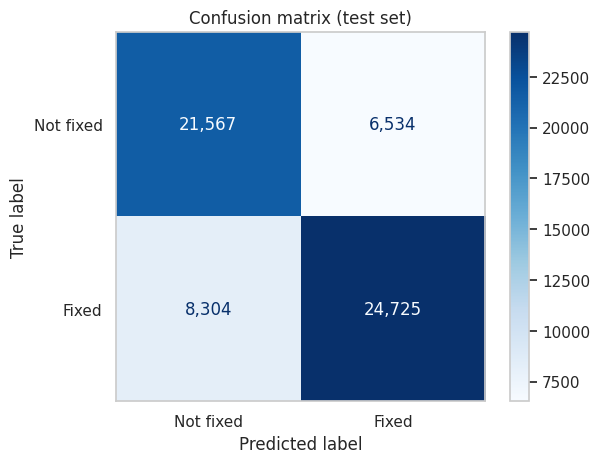

In [ ]:
y_pred = model.predict(X_test)
print("=== Logistic Regression on test set ===")
print(classification_report(y_test, y_pred, target_names=["Not fixed", "Fixed"]))

print(f"Macro F1  baseline: {f1_score(y_test, dummy_pred, average='macro'):.3f}  |  "
      f"model: {f1_score(y_test, y_pred, average='macro'):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Not fixed", "Fixed"],
                                        cmap="Blues", values_format=",")
plt.title("Confusion matrix (test set)")
plt.grid(False)
plt.show()

### 10.8 Explain the model: which factors matter most
**Purpose:** Show which words and categories push the prediction toward "Fixed" or "Not fixed".

**Requirement:** `model` is trained.

**Logic:** Each feature has a coefficient. A large positive value means more likely fixed, and a large negative value means less likely fixed. Print the top 15 of each.

**Why this way:** An explainable model is far more useful to a business than a black box. For example, it can reveal that "screen" or "battery" problems are usually fixable while some categories rarely are. This directly answers the business question of *which factors are associated with unsuccessful repairs*.

In [ ]:
feature_names = model.named_steps["prep"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefs}).sort_values("coefficient")

print("=== Top 15 signals for NOT FIXED ===")
print(coef_df.head(15).to_string(index=False))
print("\n=== Top 15 signals for FIXED ===")
print(coef_df.tail(15).iloc[::-1].to_string(index=False))

=== Top 15 signals for NOT FIXED ===
           feature  coefficient
       text__kopen    -8.016683
   text__bestellen    -5.925268
text__te vervangen    -5.683830
 text__be replaced    -5.326160
   text__not fixed    -5.180173
 text__irréparable    -5.050113
  text__impossible    -5.001770
      text__leider    -4.983973
   text__commander    -4.875030
   text__remplacer    -4.674117
     text__acheter    -4.651992
 text__aanschaffen    -4.556741
  text__specialist    -4.555784
      text__beyond    -4.267318
       text__nötig    -4.218673

=== Top 15 signals for FIXED ===
            feature  coefficient
     text__replaced    10.460076
text__schoongemaakt     9.800824
   text__gemonteerd     9.692984
    text__vervangen     9.323518
    text__geplaatst     8.111950
      text__cleaned     7.933233
   text__gesoldeerd     7.926234
        text__fixed     7.667545
  text__gerepareerd     7.602244
       text__fitted     7.556140
    text__vastgezet     7.276399
     text__hersteld  

---
## 11. Summary of fixes (mapped to the code review)

| Review item | Problem in original | Fix in this notebook | Section |
|---|---|---|---|
| Error 1 | Download could fail or prompt; unknown file name | `gdown -O aggregate.zip`, `unzip -o`, file-existence check | 2.1–2.2 |
| Error 2 | Category columns renamed blindly | Column count and type/order check before renaming, plus ID-to-name check | 3.2, 9.2 |
| Error 3 | Missing columns cause `KeyError` | Required-column check with a clear message | 3.1 |
| Error 4 / Issue 3 | Median imputation of IDs and of ~67% missing ages | No blind imputation; missing values handled inside the ML pipeline with a "missing" flag | 4.4, 10.4 |
| Error 5 | Age cutoff 40 in one cell, 50 in another | One constant `AGE_MAX`, one cleaning function used everywhere | 1.2, 4 |
| Error 6 | `astype(int)` silently truncated ages | Decimals kept; explicit `floor` (completed years) only for discrete models | 4.3, 8.1 |
| Error 7 | PCA included category ID | IDs and codes excluded; result interpreted with correlations | 6 |
| Error 8 | Fit judged by eye only | Dispersion check, Negative Binomial added, chi-square test and TVD | 8.2–8.5 |
| Error 9 | Plot cut at age 30 | Axis covers the full range | 8.4 |
| Error 10 | `product_age INT` in SQL | `DECIMAL(5,2)`, chosen from the data | 4.6, 9.3 |
| Error 11 | No foreign-key validation | Primary key, foreign key and name checks before loading | 9.2 |
| Section 6 | No ML model | Leakage-free baseline: Dummy vs. Logistic Regression, with precision, recall, F1, confusion matrix and explanations | 10 |
| Extra | Seaborn `FutureWarning`; Colab-only download crashed elsewhere | `hue=` with `legend=False`; `try/except` around Colab import | 7.2, 9.4 |

**Limitation to state in the report:** This is community repair-café data (volunteers, many product types, many languages), not a commercial appliance-repair chain. It is ideal for learning *which products and faults are fixable*. Business data like cost, duration and technician details is not included, so the team's synthetic dataset covers those parts.